# EDA

### import the dependencies

In [51]:
import re
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [26]:
df = pd.read_csv("../data/fake_news_dataset.csv")

In [27]:
df.head()

,title,text,date,source,author,category,label
0,Foreign Democrat final.,more tax development both store agreement lawy...,2023-03-10,NY Times,Paula George,Politics,real
1,To offer down resource great point.,probably guess western behind likely next inve...,2022-05-25,Fox News,Joseph Hill,Politics,fake
2,Himself church myself carry.,them identify forward present success risk sev...,2022-09-01,CNN,Julia Robinson,Business,fake
3,You unit its should.,phone which item yard Republican safe where po...,2023-02-07,Reuters,Mr. David Foster DDS,Science,fake
4,Billion believe employee summer how.,wonder myself fact difficult course forget exa...,2023-04-03,CNN,Austin Walker,Technology,fake


In [28]:
label_counts = df['label'].value_counts()
label_counts

label
fake    10056
real     9944
Name: count, dtype: int64

### before removing nulls labels are Approximately balanced

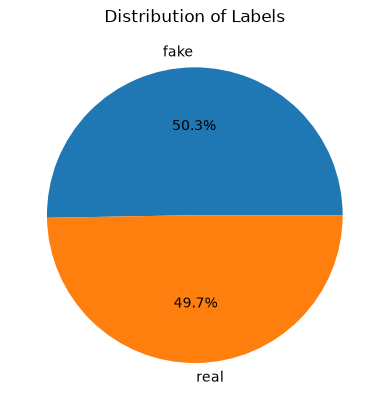

In [29]:
plt.pie(label_counts, labels=label_counts.index, autopct='%1.1f%%')
plt.title('Distribution of Labels')
plt.show()

In [30]:
df.isnull().sum()

title          0
text           0
date           0
source      1000
author      1000
category       0
label          0
dtype: int64

In [31]:
df.dropna(inplace=True)
df.isnull().sum()

C:\Users\ahmed\AppData\Local\Temp\ipykernel_13620\3641017954.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace=True)


title       0
text        0
date        0
source      0
author      0
category    0
label       0
dtype: int64

In [32]:
label_counts = df['label'].value_counts()
label_counts

label
fake    9095
real    8950
Name: count, dtype: int64

### after removing nulls labels are Approximately balanced

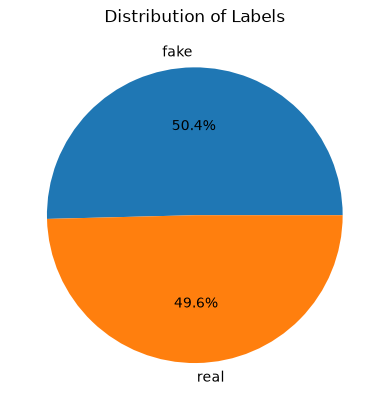

In [33]:
plt.pie(label_counts, labels=label_counts.index, autopct='%1.1f%%')
plt.title('Distribution of Labels')
plt.show()

In [34]:
df["label"] = df["label"].map({"fake": 0, "real": 1})
df["label"].value_counts()

label
0    9095
1    8950
Name: count, dtype: int64

### average of text length

In [36]:
df["n_words"] = df["text"].fillna("").str.split().str.len()

print(df["n_words"].describe())

count    18045.000000
mean       250.156442
std         29.081117
min        200.000000
25%        225.000000
50%        250.000000
75%        275.000000
max        300.000000
Name: n_words, dtype: float64


In [37]:
print(df.groupby("label")["n_words"].describe())

        count        mean        std    min    25%    50%    75%    max
label                                                                  
0      9095.0  249.952831  29.258099  200.0  225.0  250.0  275.0  300.0
1      8950.0  250.363352  28.900321  200.0  225.0  250.0  275.0  300.0


In [38]:
print(df["n_words"].quantile([0.5, 0.75, 0.9, 0.95, 0.99]))

0.50    250.0
0.75    275.0
0.90    290.0
0.95    295.0
0.99    300.0
Name: n_words, dtype: float64


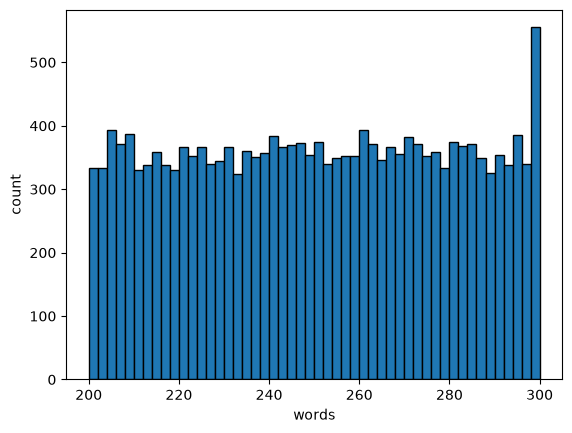

In [41]:
plt.hist(df["n_words"],bins=50,edgecolor='black')
plt.xlabel("words")
plt.ylabel("count")
plt.show()

In [47]:
print(pd.crosstab(df["source"], df["label"]))
print('-------------------------------------------------------')
print(pd.crosstab(df["category"], df["label"]))
print('-------------------------------------------------------')
print(df.groupby("label")["author"].apply(lambda s: s.isna().mean()))
print('-------------------------------------------------------')
print(df.groupby("label")["date"].agg(["min", "max"]))

label            0     1
source                  
BBC           1126  1154
CNN           1142  1125
Daily News    1168  1148
Fox News      1141  1110
Global Times  1117  1079
NY Times      1159  1083
Reuters       1125  1114
The Guardian  1117  1137
-------------------------------------------------------
label             0     1
category                 
Business       1334  1242
Entertainment  1324  1283
Health         1340  1282
Politics       1251  1267
Science        1245  1266
Sports         1317  1295
Technology     1284  1315
-------------------------------------------------------
label
0    0.0
1    0.0
Name: author, dtype: float64
-------------------------------------------------------
              min         max
label                        
0      2022-04-26  2025-04-25
1      2022-04-26  2025-04-25


In [48]:
print(df.duplicated(subset="text").sum())

0


In [50]:
df['combined_text'] = df['title'] + ' ' + df['text']
df['combined_text']

0        Foreign Democrat final. more tax development b...
1        To offer down resource great point. probably g...
2        Himself church myself carry. them identify for...
3        You unit its should. phone which item yard Rep...
4        Billion believe employee summer how. wonder my...
                               ...                        
19995    House party born. hit and television I change ...
19996    Though nation people maybe price box. fear mos...
19997    Yet exist with experience unit. activity loss ...
19998    School wide itself item. term point general co...
19999    Offer chair cover senior born. remain pressure...
Name: combined_text, Length: 18045, dtype: str

In [ ]:
def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = re.sub(r"^.{0,60}?\((Reuters|AP|AFP)\)\s*[-–—]?\s*", "", text)  # EX "WASHINGTON (Reuters) -"
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)                      # links
    text = re.sub(r"<[^>]+>", " ", text)                                    # HTML Tags
    text = re.sub(r"\s+", " ", text)                                        # extra spaces
    return text.strip()